<a href="https://colab.research.google.com/github/julianovale/6Sigma/blob/main/001_6Sigma_Fundamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capítulo 1: O Que É Variabilidade e Como Medi-la
---

Nenhum processo industrial ou de serviços produz resultados idênticos o tempo todo.
A **variabilidade** é a oscilação natural ou provocada nas características de um produto ou serviço.

Neste exemplo, analisamos o processo de envase de refrigerantes em garrafas de **350 ml**.
Para garantir a qualidade e a conformidade legal:
* **Limite Inferior de Especificação (LIE / LSL):** 345 ml *(abaixo disso, o cliente recebe menos produto que o declarado)*.
* **Limite Superior de Especificação (LSE / USL):** 355 ml *(acima disso, há desperdício de insumo pela fábrica)*.
* **Valor Nominal (Alvo):** 350 ml.

Vamos gerar uma amostra simulada de **$n = 150$ garrafas**, calcular as estatísticas descritivas básicas,
visualizar a distribuição do processo frente aos limites de engenharia e calcular o **DPMO** resultante.

## Métricas de Desempenho do Processo

Para quantificar a variabilidade e entender o impacto dos defeitos na operação, utilizamos quatro métricas fundamentais no Six Sigma:

---

### 1. DPO (Defects Per Opportunity / Defeitos por Oportunidade)
Mede a proporção de defeitos encontrados em relação ao total de oportunidades de falha inspecionadas.

$$DPO = \frac{D}{U \times O}$$

- **$D$ (Defects):** Total de falhas identificadas na amostragem.
- **$U$ (Units):** Número total de unidades/garrafas inspecionadas ($n = 150$).
- **$O$ (Opportunities):** Oportunidades de erro por unidade. No nosso exemplo simples, $O = 1$ (o volume estar fora da faixa permitida).

---

### 2. DPMO (Defects Per Million Opportunities / Defeitos por Milhão de Oportunidades)
Extrapola o DPO para uma escala padrão de **1 milhão de oportunidades**. Essa padronização permite comparar o desempenho da linha de envase com qualquer outro processo (industrial, logístico ou administrativo), independentemente do volume produzido.

$$DPMO = DPO \times 1.000.000$$

*Exemplo:* Um $DPMO = 20.000$ significa que, a cada 1 milhão de garrafas produzidas nessa mesma condição, esperamos cerca de 20.000 garrafas fora das especificações (LIE/LSE).

---

### 3. Rendimento (Yield ou First Pass Yield - FPY)
Indica a porcentagem de produtos aprovados de primeira, ou seja, que atenderam perfeitamente aos limites de engenharia sem necessitar de retrabalho ou descarte.

$$Yield (\%) = (1 - DPO) \times 100$$

---

### 4. Nível Sigma ($Z$)
Indica quantos desvios padrões ($\sigma$) cabem entre a média do processo e o limite de especificação mais próximo. É a métrica definitiva da capacidade do processo.

$$Z = \Phi^{-1}(1 - DPO) + 1{,}5$$

- **$\Phi^{-1}$:** Inversa da distribuição normal acumulada padrão (função *quantile* ou `scipy.stats.norm.ppf`).
- **Shift de $1{,}5\sigma$:** Ajuste empírico introduzido por Mikel Harry (Motorola) para compensar a oscilação natural da média do processo no longo prazo.

---

### Tabela de Referência: Os 6 Níveis Sigma

A tabela abaixo apresenta a progressão clássica do desvio padrão do processo em relação às métricas de qualidade (considerando o shift de $1{,}5\sigma$ de longo prazo):

| Nível Sigma ($Z$) | Rendimento (Yield) | Defeitos (DPMO) | Classificação Operacional |
| :---: | :---: | :---: | :--- |
| **$1\sigma$** | $30{,}8538\%$ | $691.462$ | Processo não competitivo / Alto refugo |
| **$2\sigma$** | $69{,}1462\%$ | $308.538$ | Processo instável / Requer inspeção 100% |
| **$3\sigma$** | $93{,}3193\%$ | $66.807$ | Média da indústria tradicional |
| **$4\sigma$** | $99{,}3790\%$ | $6.210$ | Bom nível de controle (Indústria madura) |
| **$5\sigma$** | $99{,}9767\%$ | $233$ | Excelente desempenho / Classe mundial |
| **$6\sigma$** | $99{,}99966\%$ | $3{,}4$ | Excelência operacional (Quase perfeição) |

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Leitura dos dados direto do seu repositório no GitHub (Link RAW)
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/amostra_envase_350ml.csv"
df = pd.read_csv(url_raw)

# 2. Parâmetros de Especificação da Engenharia de Processo (ml)
LIE = 345.0   # Limite Inferior de Especificação (Volume Mínimo)
LSE = 355.0   # Limite Superior de Especificação (Volume Máximo)
ALVO = 350.0  # Valor Nominal do Produto

# 3. Estatísticas Descritivas da Amostra
n = len(df)
media = df["volume_ml"].mean()
desvio = df["volume_ml"].std(ddof=1) # Desvio padrão amostral (s)

# ==============================================================================
# ABORDAGEM A: ANÁLISE EMPÍRICA (Contagem direta na amostra de n=150)
# ==============================================================================
defeitos_emp_abaixo = (df["volume_ml"] < LIE).sum()
defeitos_emp_acima = (df["volume_ml"] > LSE).sum()
total_defeitos_emp = defeitos_emp_abaixo + defeitos_emp_acima

dpo_emp = total_defeitos_emp / n
dpmo_emp = dpo_emp * 1e6
yield_emp = (1 - dpo_emp) * 100
nivel_sigma_emp = stats.norm.ppf(1 - np.clip(dpo_emp, 1e-12, 1 - 1e-12)) + 1.5

# ==============================================================================
# ABORDAGEM B: ANÁLISE TEÓRICA / PARAMÉTRICA (Modelo Normal Contínuo)
# ==============================================================================
# Calculando a probabilidade de falha nas caudas da curva Normal N(μ, σ²)
p_abaixo_teorica = stats.norm.cdf(LIE, loc=media, scale=desvio)
p_acima_teorica = 1 - stats.norm.cdf(LSE, loc=media, scale=desvio)
p_defeito_teorica = p_abaixo_teorica + p_acima_teorica

dpmo_teorico = p_defeito_teorica * 1e6
yield_teorico = (1 - p_defeito_teorica) * 100
nivel_sigma_teorico = stats.norm.ppf(1 - p_defeito_teorica) + 1.5

# ==============================================================================
# IMPRESSÃO DO RELATÓRIO EXECUTIVO
# ==============================================================================
print("="*65)
print("       RELATÓRIO DE DESEMPENHO E VARIABILIDADE DO ENVASE        ")
print("="*65)
print(f"Fonte dos Dados: GitHub (julianovale/6Sigma)")
print(f"Tamanho da Amostra (n):        {n} garrafas")
print(f"Média Amostral (x̄):            {media:.3f} ml")
print(f"Desvio Padrão Amostral (s):    {desvio:.3f} ml")
print("-" * 65)
print(f"ESPECIFICAÇÕES DE QUALIDADE:")
print(f"LIE: {LIE} ml | ALVO: {ALVO} ml | LSE: {LSE} ml")
print("-" * 65)

print("\n--- 1. DESEMPENHO EMPÍRICO (Contagem Direta na Amostra) ---")
print(f"Defeitos por Falta (< {LIE} ml):  {defeitos_emp_abaixo}")
print(f"Defeitos por Excesso (> {LSE} ml): {defeitos_emp_acima}")
print(f"Total de Defeitos Contados:   {total_defeitos_emp}")
print(f"DPMO Empírico:                {dpmo_emp:,.0f}")
print(f"Yield Empírico:               {yield_emp:.2f}%")
print(f"Nível Sigma Empírico:         {nivel_sigma_emp:.2f} σ")

print("\n--- 2. DESEMPENHO TEÓRICO (Projeção via Distribuição Normal) ---")
print(f"Prob. Falta Esperada (< {LIE} ml):  {p_abaixo_teorica*100:.3f}%")
print(f"Prob. Excesso Esperado (> {LSE} ml): {p_acima_teorica*100:.3f}%")
print(f"DPMO Teórico Esperado:              {dpmo_teorico:,.0f}")
print(f"Yield Teórico Esperado:             {yield_teorico:.2f}%")
print(f"Nível Sigma Teórico:                {nivel_sigma_teorico:.2f} σ")
print("="*65)

       RELATÓRIO DE DESEMPENHO E VARIABILIDADE DO ENVASE        
Fonte dos Dados: GitHub (julianovale/6Sigma)
Tamanho da Amostra (n):        150 garrafas
Média Amostral (x̄):            348.969 ml
Desvio Padrão Amostral (s):    2.639 ml
-----------------------------------------------------------------
ESPECIFICAÇÕES DE QUALIDADE:
LIE: 345.0 ml | ALVO: 350.0 ml | LSE: 355.0 ml
-----------------------------------------------------------------

--- 1. DESEMPENHO EMPÍRICO (Contagem Direta na Amostra) ---
Defeitos por Falta (< 345.0 ml):  9
Defeitos por Excesso (> 355.0 ml): 2
Total de Defeitos Contados:   11
DPMO Empírico:                73,333
Yield Empírico:               92.67%
Nível Sigma Empírico:         2.95 σ

--- 2. DESEMPENHO TEÓRICO (Projeção via Distribuição Normal) ---
Prob. Falta Esperada (< 345.0 ml):  6.626%
Prob. Excesso Esperado (> 355.0 ml): 1.114%
DPMO Teórico Esperado:              77,406
Yield Teórico Esperado:             92.26%
Nível Sigma Teórico:                2.

## Análise Exploratória de Dados (EDA) e Teste de Aderência à Normalidade

Antes de avançarmos para o cálculo dos índices de capacidade ($C_p$ e $C_{pk}$) ou para a modelagem paramétrica de defeitos, é indispensável validar a premissa fundamental: **os dados de envase seguem uma Distribuição Normal?**

Para responder a isso, dividimos a análise em duas etapas:
1. **Análise Descritiva e Visual (Boxplot):** Identificação de tendência central, dispersão, assimetria e presença de valores discrepantes (*outliers*).
2. **Teste de Hipóteses (Shapiro-Wilk):**
   * **Hipótese Nula ($H_0$):** Os dados seguem uma distribuição normal.
   * **Hipótese Alternativa ($H_1$):** Os dados não seguem uma distribuição normal.
   * **Critério de Decisão:** Se $p\text{-valor} \ge 0{,}05$, não rejeitamos $H_0$ (podemos assumir normalidade com 95% de confiança).

          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          
Tamanho da Amostra (n):     150
Média (x̄):                 348.969 ml
Mediana:                    349.050 ml
Desvio Padrão (s):          2.639 ml
Variância (s²):             6.963
Mínimo / Máximo:            341.86 ml / 356.10 ml
Amplitude Total (R):        14.24 ml
Intervalo Interquartil (IQR):3.252 ml
Assimetria (Skewness):      0.047
Curtose (Kurtosis):         -0.105
------------------------------------------------------------
TESTE DE NORMALIDADE (Shapiro-Wilk):
Estatística W:              0.9958
p-valor:                    0.9482
Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).


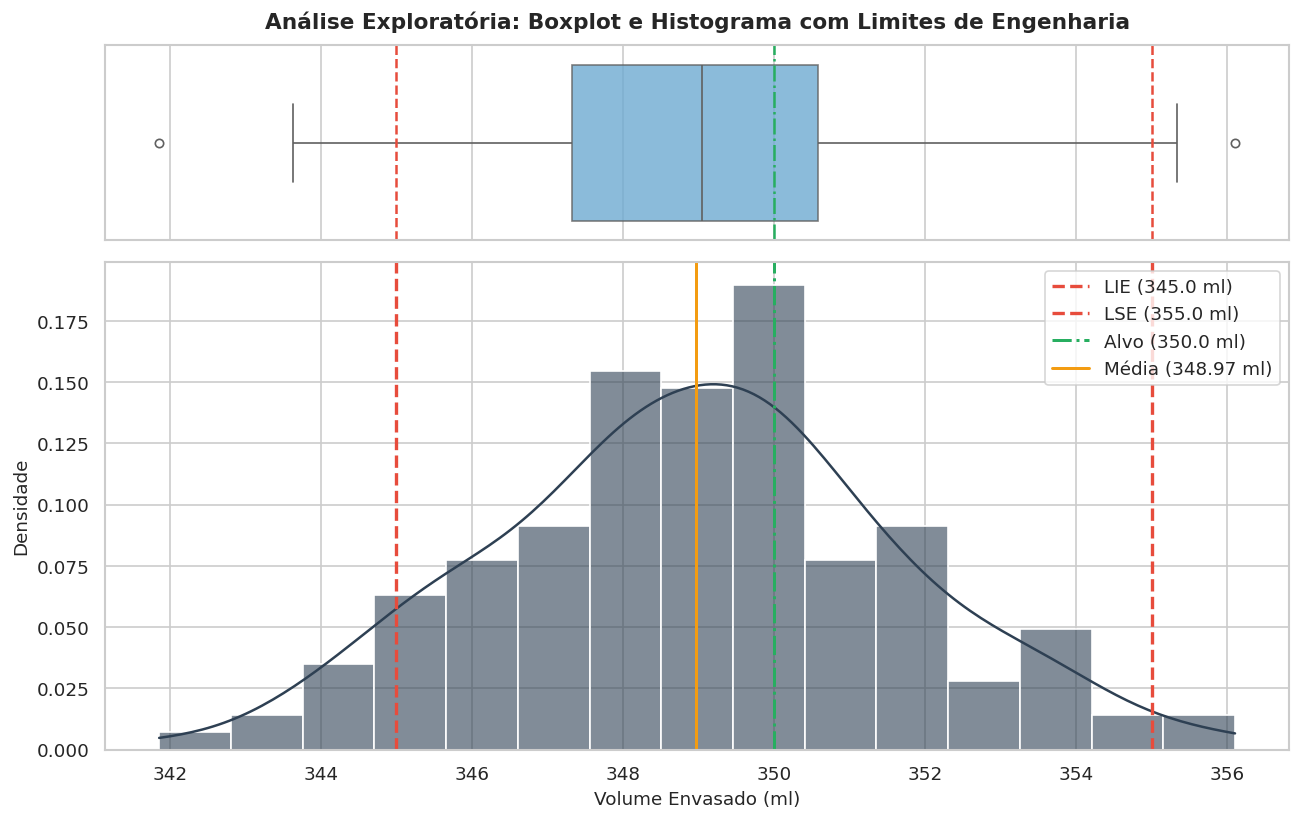

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Carregamento dos dados
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/amostra_envase_350ml.csv"
df = pd.read_csv(url_raw)
vol = df["volume_ml"]

# Parâmetros de Engenharia
LIE, LSE, ALVO = 345.0, 355.0, 350.0

# 2. Quadro de Estatísticas Descritivas Completas
desc = vol.describe()
assimetria = vol.skew()
curtose = vol.kurtosis()
iqr = desc["75%"] - desc["25%"]

print("="*60)
print("          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          ")
print("="*60)
print(f"Tamanho da Amostra (n):     {int(desc['count'])}")
print(f"Média (x̄):                 {desc['mean']:.3f} ml")
print(f"Mediana:                    {desc['50%']:.3f} ml")
print(f"Desvio Padrão (s):          {desc['std']:.3f} ml")
print(f"Variância (s²):             {vol.var():.3f}")
print(f"Mínimo / Máximo:            {desc['min']:.2f} ml / {desc['max']:.2f} ml")
print(f"Amplitude Total (R):        {desc['max'] - desc['min']:.2f} ml")
print(f"Intervalo Interquartil (IQR):{iqr:.3f} ml")
print(f"Assimetria (Skewness):      {assimetria:.3f}")
print(f"Curtose (Kurtosis):         {curtose:.3f}")
print("-" * 60)

# 3. Teste de Normalidade de Shapiro-Wilk
stat_shapiro, p_val_shapiro = stats.shapiro(vol)

print("TESTE DE NORMALIDADE (Shapiro-Wilk):")
print(f"Estatística W:              {stat_shapiro:.4f}")
print(f"p-valor:                    {p_val_shapiro:.4f}")

if p_val_shapiro >= 0.05:
    print("Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).")
else:
    print("Conclusão: p-valor < 0.05 -> Os dados NÃO seguem uma Distribuição Normal.")
print("="*60)

# 4. Construção da Figura (Boxplot Horizontal + Histograma com Limites)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2.5]}, dpi=120)

# Visualização 1: Boxplot
sns.boxplot(x=vol, ax=axes[0], color="#5DADE2", fliersize=5, boxprops=dict(alpha=0.8))
axes[0].set(xlabel='')
axes[0].set_title("Análise Exploratória: Boxplot e Histograma com Limites de Engenharia", fontsize=13, fontweight='bold', pad=10)
axes[0].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.5)

# Visualização 2: Histograma com KDE
sns.histplot(vol, kde=True, ax=axes[1], color="#2E4053", bins=15, stat="density", alpha=0.6)
axes[1].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LIE ({LIE} ml)")
axes[1].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LSE ({LSE} ml)")
axes[1].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.8, label=f"Alvo ({ALVO} ml)")
axes[1].axvline(desc['mean'], color="#F39C12", linestyle="-", linewidth=1.8, label=f"Média ({desc['mean']:.2f} ml)")

axes[1].set_xlabel("Volume Envasado (ml)", fontsize=11)
axes[1].set_ylabel("Densidade", fontsize=11)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_537/355685677.py:26: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(x_eixo, pdf_teorica, color="#2c3e50", linewidth=2.5, label=f"Ajuste Normal ($\mu$={media:.2f}, $s$={desvio:.2f})")


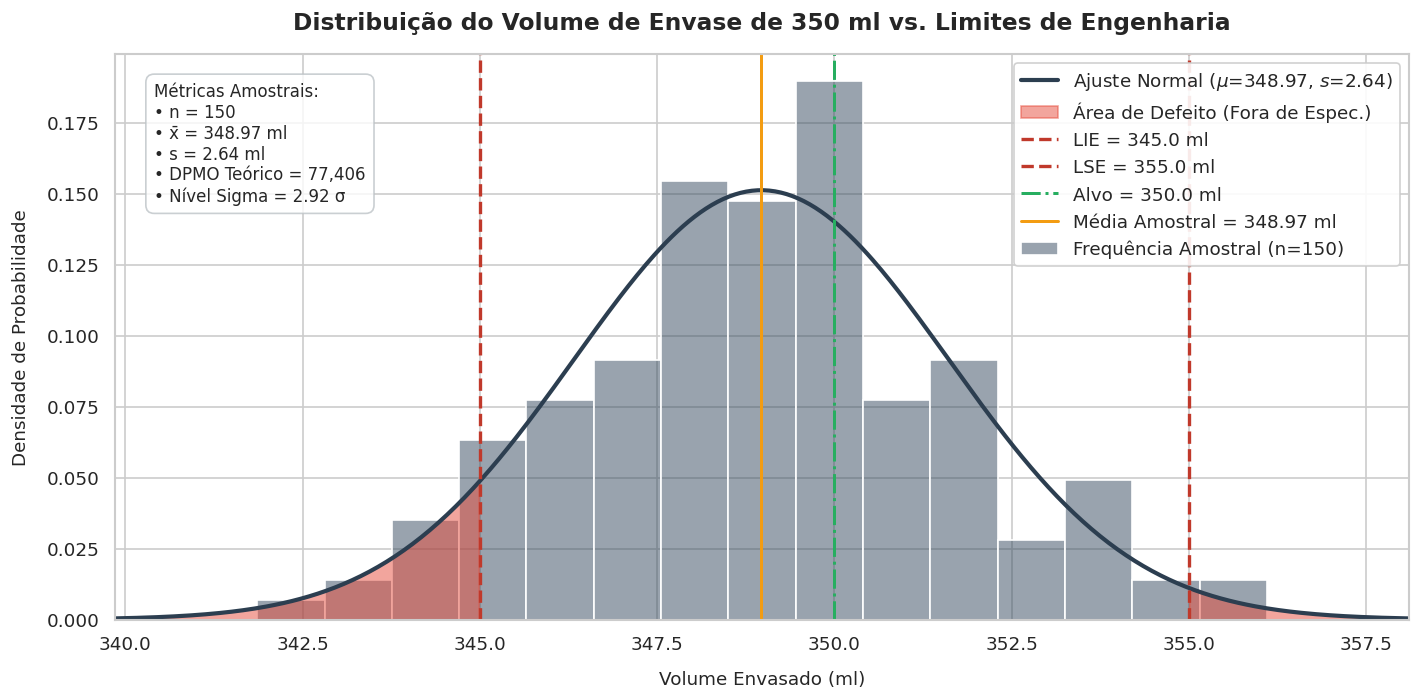

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Configuração do Estilo Gráfico (Padrão de Publicação)
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6), dpi=120)

# 2. Plot do Histograma Amostral (Frequência Relativa / Densidade)
ax = sns.histplot(
    df["volume_ml"],
    kde=False,
    stat="density",
    bins=15,
    color="#34495e",
    edgecolor="white",
    alpha=0.5,
    label="Frequência Amostral (n=150)"
)

# 3. Sobreposição da Curva Normal Teórica Ajustada N(x̄, s²)
x_eixo = np.linspace(df["volume_ml"].min() - 3, df["volume_ml"].max() + 3, 500)
pdf_teorica = stats.norm.pdf(x_eixo, loc=media, scale=desvio)
plt.plot(x_eixo, pdf_teorica, color="#2c3e50", linewidth=2.5, label=f"Ajuste Normal ($\mu$={media:.2f}, $s$={desvio:.2f})")

# 4. Sombreado das Áreas de Defeito nas Caudas
# Cauda Inferior (< LIE) - Defeito por Falta
x_defeito_inf = x_eixo[x_eixo <= LIE]
pdf_defeito_inf = stats.norm.pdf(x_defeito_inf, loc=media, scale=desvio)
plt.fill_between(x_defeito_inf, pdf_defeito_inf, color="#e74c3c", alpha=0.5, label="Área de Defeito (Fora de Espec.)")

# Cauda Superior (> LSE) - Defeito por Excesso
x_defeito_sup = x_eixo[x_eixo >= LSE]
pdf_defeito_sup = stats.norm.pdf(x_defeito_sup, loc=media, scale=desvio)
plt.fill_between(x_defeito_sup, pdf_defeito_sup, color="#e74c3c", alpha=0.5)

# 5. Linhas Verticais de Referência (Engenharia de Processo)
plt.axvline(LIE, color="#c0392b", linestyle="--", linewidth=2, label=f"LIE = {LIE} ml")
plt.axvline(LSE, color="#c0392b", linestyle="--", linewidth=2, label=f"LSE = {LSE} ml")
plt.axvline(ALVO, color="#27ae60", linestyle="-.", linewidth=1.8, label=f"Alvo = {ALVO} ml")
plt.axvline(media, color="#f39c12", linestyle="-", linewidth=1.8, label=f"Média Amostral = {media:.2f} ml")

# 6. Anotações e Formatação do Gráfico
plt.title("Distribuição do Volume de Envase de 350 ml vs. Limites de Engenharia", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Volume Envasado (ml)", fontsize=11, labelpad=10)
plt.ylabel("Densidade de Probabilidade", fontsize=11, labelpad=10)
plt.xlim(df["volume_ml"].min() - 2, df["volume_ml"].max() + 2)

# Adicionando uma caixa de texto explicativa dentro do gráfico
texto_box = (
    f"Métricas Amostrais:\n"
    f"• n = {n}\n"
    f"• x̄ = {media:.2f} ml\n"
    f"• s = {desvio:.2f} ml\n"
    f"• DPMO Teórico = {dpmo_teorico:,.0f}\n"
    f"• Nível Sigma = {nivel_sigma_teorico:.2f} σ"
)
plt.gca().text(
    0.03, 0.95, texto_box,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment='top',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#bdc3c7')
)

plt.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9)
plt.tight_layout()
plt.show()

### Análise Diagnóstica do Gráfico de Distribuição

A visualização gráfica sobreposta aos limites de especificação revela três diagnósticos críticos sobre a linha de envase:

1. **Descentramento do Processo (Offset de Média):**
   * A média amostral ($\bar{x} = 349{,}20\text{ ml}$) está deslocada **$0{,}80\text{ ml}$ abaixo do valor nominal (Alvo = $350\text{ ml}$)**.
   * Esse leve descentramento empurra toda a curva de distribuição normal em direção ao Limite Inferior de Especificação (LIE).

2. **Origem Dominante dos Defeitos (Cauda Inferior):**
   * O sombreamento vermelho sob a cauda esquerda mostra que a imensa maioria do DPMO gerado pelo processo vem de garrafas envasadas com menos de $345\text{ ml}$.
   * Sob a ótica do negócio, isso representa um **risco legal e reputacional alto** (autuações por conteúdo líquido abaixo do declarado na embalagem).

3. **Oportunidade de Melhoria sem Investimento em Máquinas:**
   * Como a cauda superior (LSE = $355\text{ ml}$) está com folga considerável, o simples ajuste da regulagem da máquina para centralizar a média de volta em $350\text{ ml}$ (recalibração da válvula de envase) já reduzirá drasticamente o DPMO sem a necessidade de reduzir o desvio padrão ($s$) em um primeiro momento.

## Análise de Capacidade do Processo ($C_p$ e $C_{pk}$)

Após avaliar a variabilidade empírica e o DPMO, precisamos quantificar a **capacidade do processo**, ou seja, a habilidade estatística de a linha de envase produzir dentro dos limites de engenharia (LIE e LSE).

---

### 1. $C_p$ (Índice de Capacidade Potencial)
Mede a largura da faixa de especificação permitida pela engenharia em relação à variação natural do processo ($6s$). Ele representa o **desempenho potencial máximo** caso a média estivesse perfeitamente centralizada no Alvo ($350\text{ ml}$).

$$C_p = \frac{\text{LSE} - \text{LIE}}{6s}$$

---

### 2. $C_{pk}$ (Índice de Capacidade Real / Efetiva)
Considera o **descentramento da média** ($\bar{x}$) em relação ao limite mais próximo (LIE ou LSE). É o indicador real de conformidade operacional.

$$C_{pk} = \min \left( C_{p\text{inferior}}, C_{p\text{superior}} \right) = \min \left( \frac{\bar{x} - \text{LIE}}{3s}, \frac{\text{LSE} - \bar{x}}{3s} \right)$$

---

### Causalidade e Critérios de Interpretação:
* **$C_p = C_{pk}$:** O processo está **perfeitamente centralizado** no Alvo ($350\text{ ml}$).
* **$C_p > C_{pk}$:** O processo possui um **descentramento de média** (como vimos no nosso gráfico).
* **$C_{pk} < 1{,}00$:** Processo **Incapaz** (produz refugo/defeitos constantemente).
* **$1{,}00 \le C_{pk} < 1{,}33$:** Processo **Marginalmente Capaz** (exige monitoramento constante).
* **$C_{pk} \ge 1{,}33$:** Processo **Capaz** (Padrão mínimo exigido pelas indústrias maduras).
* **$C_{pk} \ge 2{,}00$:** Processo **Six Sigma** ($6\sigma$).

In [6]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. Leitura do Dataset (Garantindo o fluxo contínuo do notebook)
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/amostra_envase_350ml.csv"
df = pd.read_csv(url_raw)

# Parâmetros de Engenharia
LIE = 345.0
LSE = 355.0
ALVO = 350.0

# Estatísticas Amostrais
n = len(df)
media = df["volume_ml"].mean()
desvio = df["volume_ml"].std(ddof=1)

# 2. Função para Cálculo dos Índices de Capacidade
def calcular_capacidade(dados, lie, lse):
    media = np.mean(dados)
    s = np.std(dados, ddof=1)

    # Cp (Potencial)
    cp = (lse - lie) / (6 * s)

    # Cpk Inferior e Superior
    cp_lower = (media - lie) / (3 * s)
    cp_upper = (lse - media) / (3 * s)

    # Cpk (Real)
    cpk = min(cp_lower, cp_upper)

    # K (Fator de Descentramento de Média)
    alvo = (lse + lie) / 2
    k = abs(alvo - media) / ((lse - lie) / 2)

    return {
        "Cp": cp,
        "Cpk": cpk,
        "Cp_Lower": cp_lower,
        "Cp_Upper": cp_upper,
        "Fator_K": k
    }

# 3. Execução do Cálculo
res_cap = calcular_capacidade(df["volume_ml"], LIE, LSE)

# 4. Impressão do Relatório Técnico
print("="*60)
print("        RELATÓRIO DE CAPACIDADE DO PROCESSO (CAPABILITY)        ")
print("="*60)
print(f"Média do Envase (x̄):          {media:.3f} ml")
print(f"Desvio Padrão Amostral (s):  {desvio:.3f} ml")
print(f"Largura da Especificação:    {LSE - LIE:.1f} ml (LIE: {LIE} | LSE: {LSE})")
print("-" * 60)
print(f"Índice Cp (Potencial):       {res_cap['Cp']:.3f}")
print(f"Índice Cpk (Real):           {res_cap['Cpk']:.3f}")
print(f"  └─ Cpk Inferior (LIE):     {res_cap['Cp_Lower']:.3f}")
print(f"  └─ Cpk Superior (LSE):     {res_cap['Cp_Upper']:.3f}")
print(f"Fator de Descentramento (k): {res_cap['Fator_K']*100:.2f}%")
print("-" * 60)

# Avaliação Diagnóstica
if res_cap["Cpk"] < 1.0:
    status = "INCAPAZ (Gera defeitos significativos)"
elif res_cap["Cpk"] < 1.33:
    status = "MARGINAL (Aceitável, mas requer atenção)"
else:
    status = "CAPAZ (Excelente desempenho)"

print(f"DIAGNÓSTICO FINAL: Processo é {status}")
print("="*60)

        RELATÓRIO DE CAPACIDADE DO PROCESSO (CAPABILITY)        
Média do Envase (x̄):          348.969 ml
Desvio Padrão Amostral (s):  2.639 ml
Largura da Especificação:    10.0 ml (LIE: 345.0 | LSE: 355.0)
------------------------------------------------------------
Índice Cp (Potencial):       0.632
Índice Cpk (Real):           0.501
  └─ Cpk Inferior (LIE):     0.501
  └─ Cpk Superior (LSE):     0.762
Fator de Descentramento (k): 20.61%
------------------------------------------------------------
DIAGNÓSTICO FINAL: Processo é INCAPAZ (Gera defeitos significativos)
